# P1 baseline — EMA 12/26 all-in / all-out, $900, 2026 Q1–Q3

Rules:
1. Buy with all $900 at the open of the first bar of 2026, regardless of the EMA state.
2. A sell signal (EMA 12 crosses below EMA 26) while holding sells every unit at the **next bar's open**.
3. A buy signal (EMA 12 crosses above EMA 26) while in cash buys with all the cash at the **next bar's open**.
4. Signals that would not change the position are ignored. Any open position is marked at the 2026-09-30 close.

Signals are confirmed on the completed candle, so every fill after the first is one bar later. Zero fees and slippage; cash earns 0%. EMAs warm up from 2025 Q4. Shaded bands mark days holding.

In [1]:
from helpers.replayer_bars import DATA_SYMBOL
from helpers.ema_signals import ema_cross, plot_ema_trades, simulate_ema
from helpers.passive_benchmarks import CAPITAL, max_drawdown, simulate

SYMBOLS = ["BTC", "ETH", "XAUT", "QQQ"]
START, END, WARMUP = "2026Q1", "2026Q3", "2025Q4"
LABEL = "2026 Q1–Q3"

bars = {symbol: ema_cross(symbol, START, END, WARMUP) for symbol in SYMBOLS}
runs = {symbol: simulate_ema(price, CAPITAL) for symbol, price in bars.items()}
passive = {symbol: simulate(price, CAPITAL) for symbol, price in bars.items()}

for symbol in SYMBOLS:
    daily, trades = runs[symbol]
    ema_eq, bh, dca = daily["equity"], passive[symbol]["buy_hold"], passive[symbol]["dca"]
    print(f"{symbol:<5} EMA ${ema_eq.iloc[-1]:>8,.2f} ({ema_eq.iloc[-1] / CAPITAL - 1:+6.1%}, maxDD {max_drawdown(ema_eq):6.1%}) | "
          f"B&H ${bh.iloc[-1]:>8,.2f} ({bh.iloc[-1] / CAPITAL - 1:+6.1%}, maxDD {max_drawdown(bh):6.1%}) | "
          f"DCA ${dca.iloc[-1]:>8,.2f} ({dca.iloc[-1] / CAPITAL - 1:+6.1%}, maxDD {max_drawdown(dca):6.1%}) | "
          f"{len(trades)} trades, {(trades['pnl'] > 0).sum()} winners, in market {(daily['units'] > 0).mean():.0%} of bars")

BTC   EMA $1,007.18 (+11.9%, maxDD -18.0%) | B&H $  858.65 ( -4.6%, maxDD -39.5%) | DCA $1,053.92 (+17.1%, maxDD -18.7%) | 7 trades, 3 winners, in market 52% of bars
ETH   EMA $1,102.20 (+22.5%, maxDD -28.2%) | B&H $  813.39 ( -9.6%, maxDD -53.3%) | DCA $1,140.75 (+26.8%, maxDD -21.7%) | 4 trades, 1 winners, in market 56% of bars
XAUT  EMA $  981.52 ( +9.1%, maxDD -14.2%) | B&H $  866.40 ( -3.7%, maxDD -26.6%) | DCA $  830.44 ( -7.7%, maxDD -13.6%) | 2 trades, 2 winners, in market 43% of bars
QQQ   EMA $  982.30 ( +9.1%, maxDD  -9.6%) | B&H $1,077.24 (+19.7%, maxDD -12.2%) | DCA $1,016.64 (+13.0%, maxDD  -8.4%) | 4 trades, 2 winners, in market 66% of bars


In [2]:
fmt = {"entry_open": "{:,.2f}".format, "exit_open": "{:,.2f}".format, "cost": "{:,.2f}".format,
       "proceeds": "{:,.2f}".format, "pnl": "{:+,.2f}".format, "return": "{:+.1%}".format}
for symbol in SYMBOLS:
    trades = runs[symbol][1].assign(entry=lambda t: t["entry"].dt.strftime("%Y-%m-%d"),
                                    exit=lambda t: t["exit"].dt.strftime("%Y-%m-%d").fillna("open @ 09-30 close"))
    print(f"\n{symbol}")
    print(trades.to_string(formatters=fmt))


BTC
        entry entry_open   cost                exit exit_open proceeds     pnl return  days
0  2026-01-01  87,643.30 900.00          2026-01-25 89,227.70   916.27  +16.27  +1.8%    24
1  2026-03-16  72,812.40 916.27          2026-03-23 67,862.00   853.97  -62.30  -6.8%     7
2  2026-03-24  70,898.70 853.97          2026-03-27 68,820.10   828.94  -25.04  -2.9%     3
3  2026-04-10  71,788.90 828.94          2026-05-23 75,540.30   872.25  +43.32  +5.2%    43
4  2026-07-16  64,756.40 872.25          2026-08-02 62,823.30   846.22  -26.04  -3.0%    17
5  2026-08-07  64,320.40 846.22          2026-08-13 63,482.90   835.20  -11.02  -1.3%     6
6  2026-08-20  69,338.40 835.20  open @ 09-30 close       NaN 1,007.18 +171.98 +20.6%    41

ETH
        entry entry_open   cost                exit exit_open proceeds     pnl return  days
0  2026-01-01   2,971.58 900.00          2026-01-23  2,952.66   894.27   -5.73  -0.6%    22
1  2026-03-17   2,352.58 894.27          2026-03-28  1,992.70   757.47

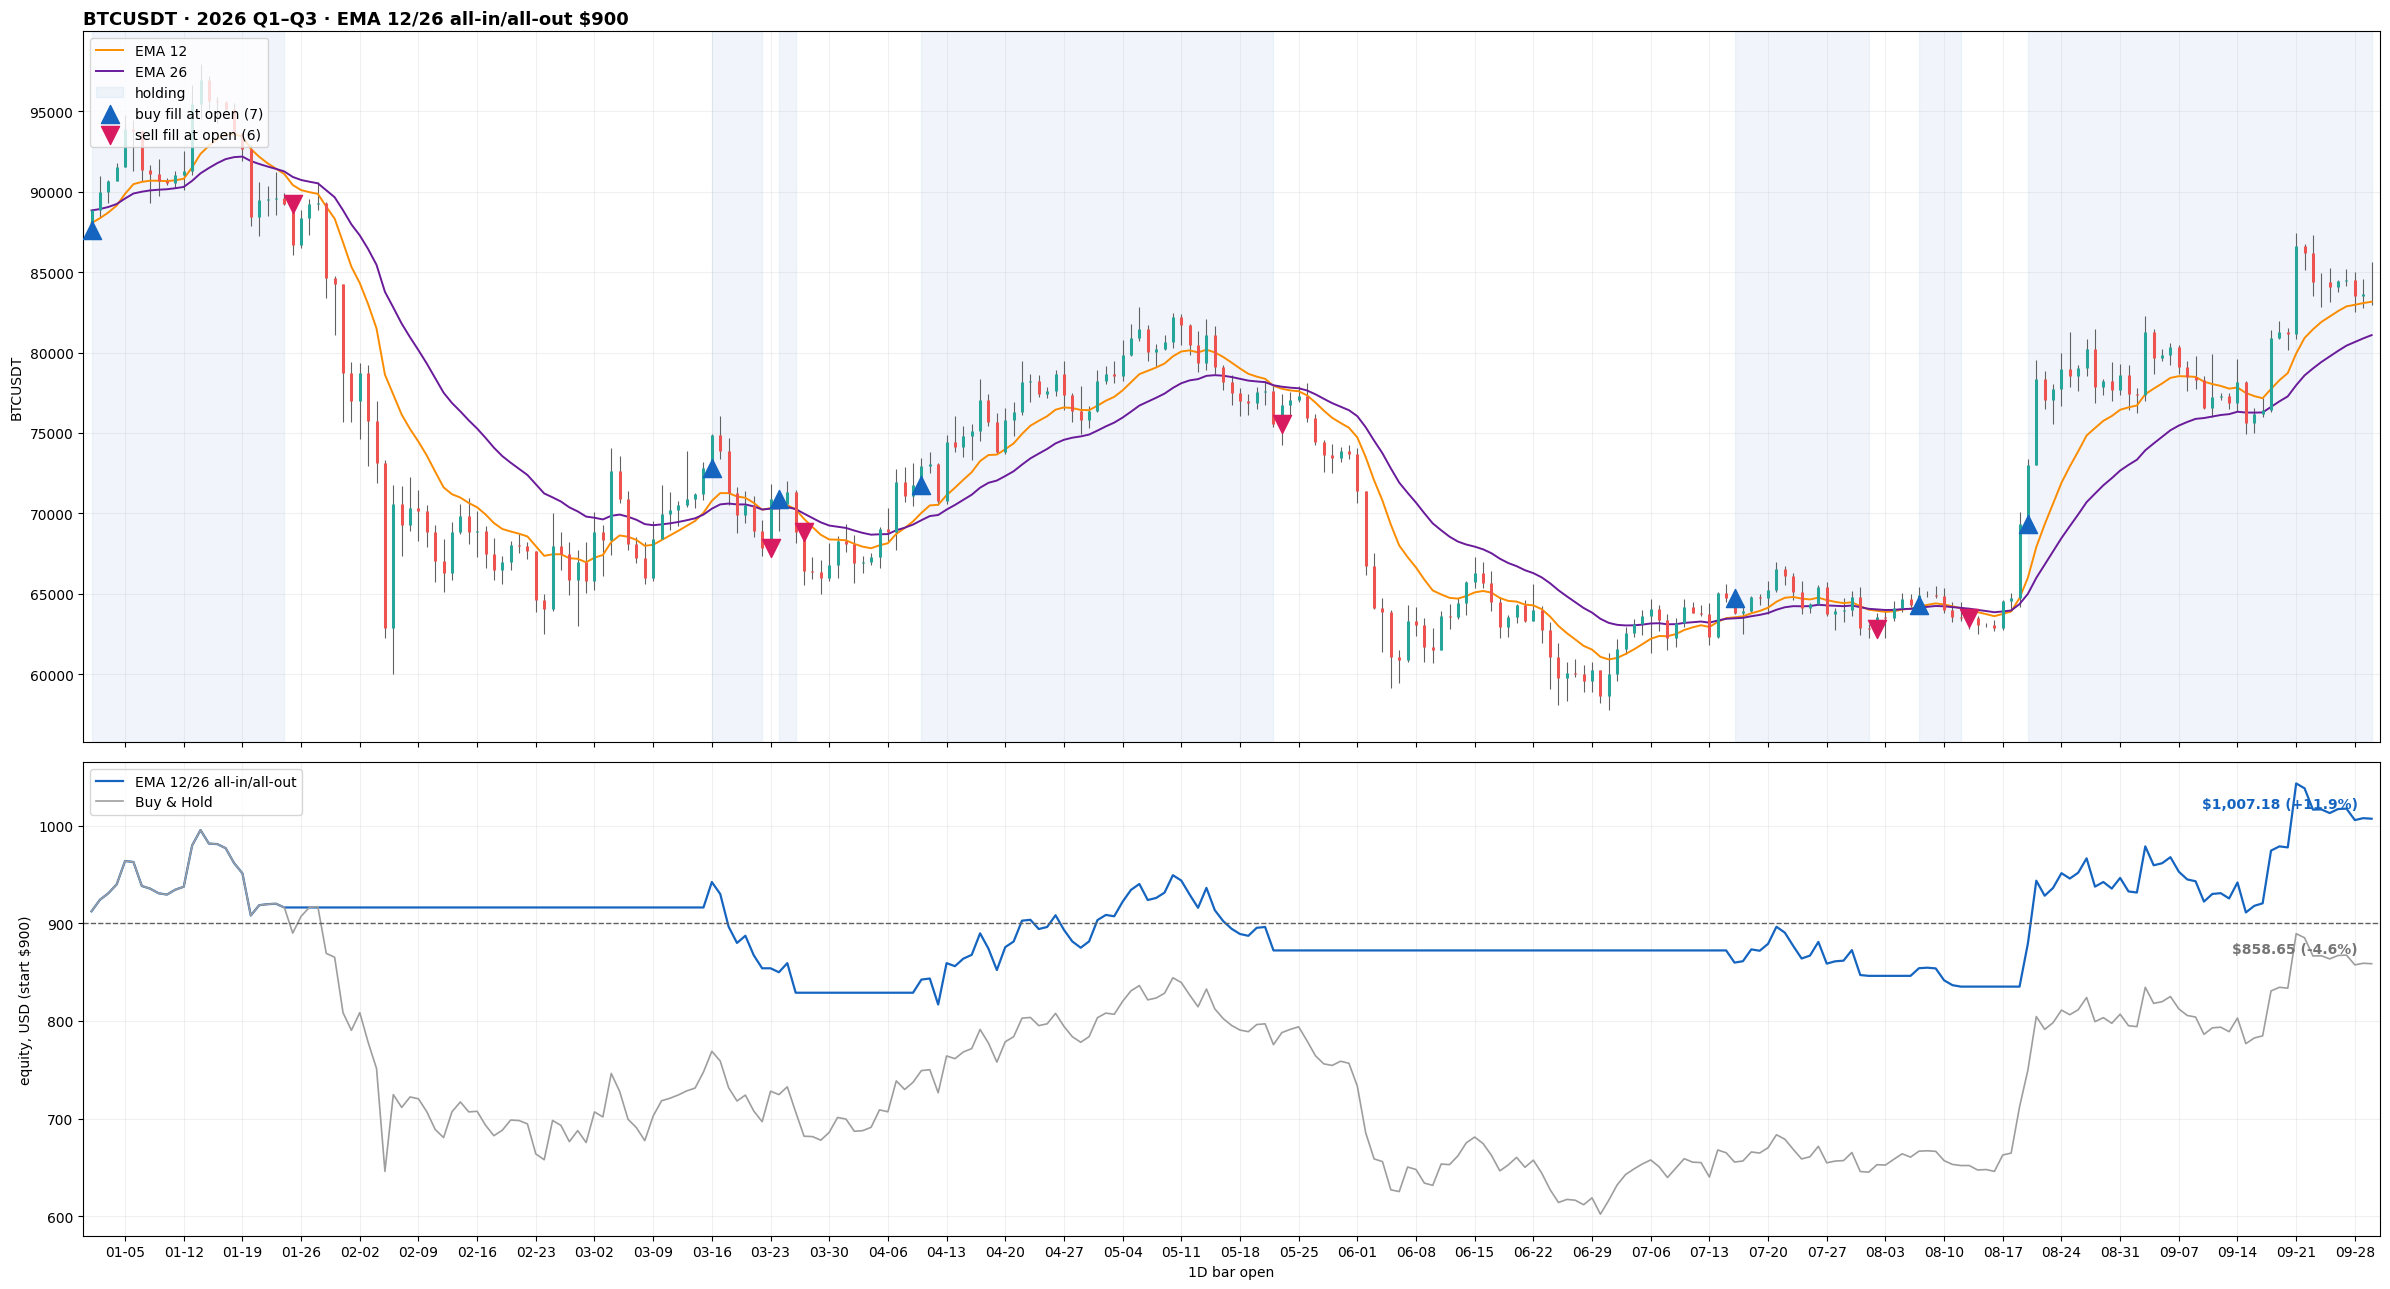

In [3]:
plot_ema_trades(bars["BTC"], runs["BTC"][0], passive["BTC"]["buy_hold"], f"BTCUSDT · {LABEL} · EMA 12/26 all-in/all-out ${CAPITAL:,.0f}", "BTCUSDT", CAPITAL)

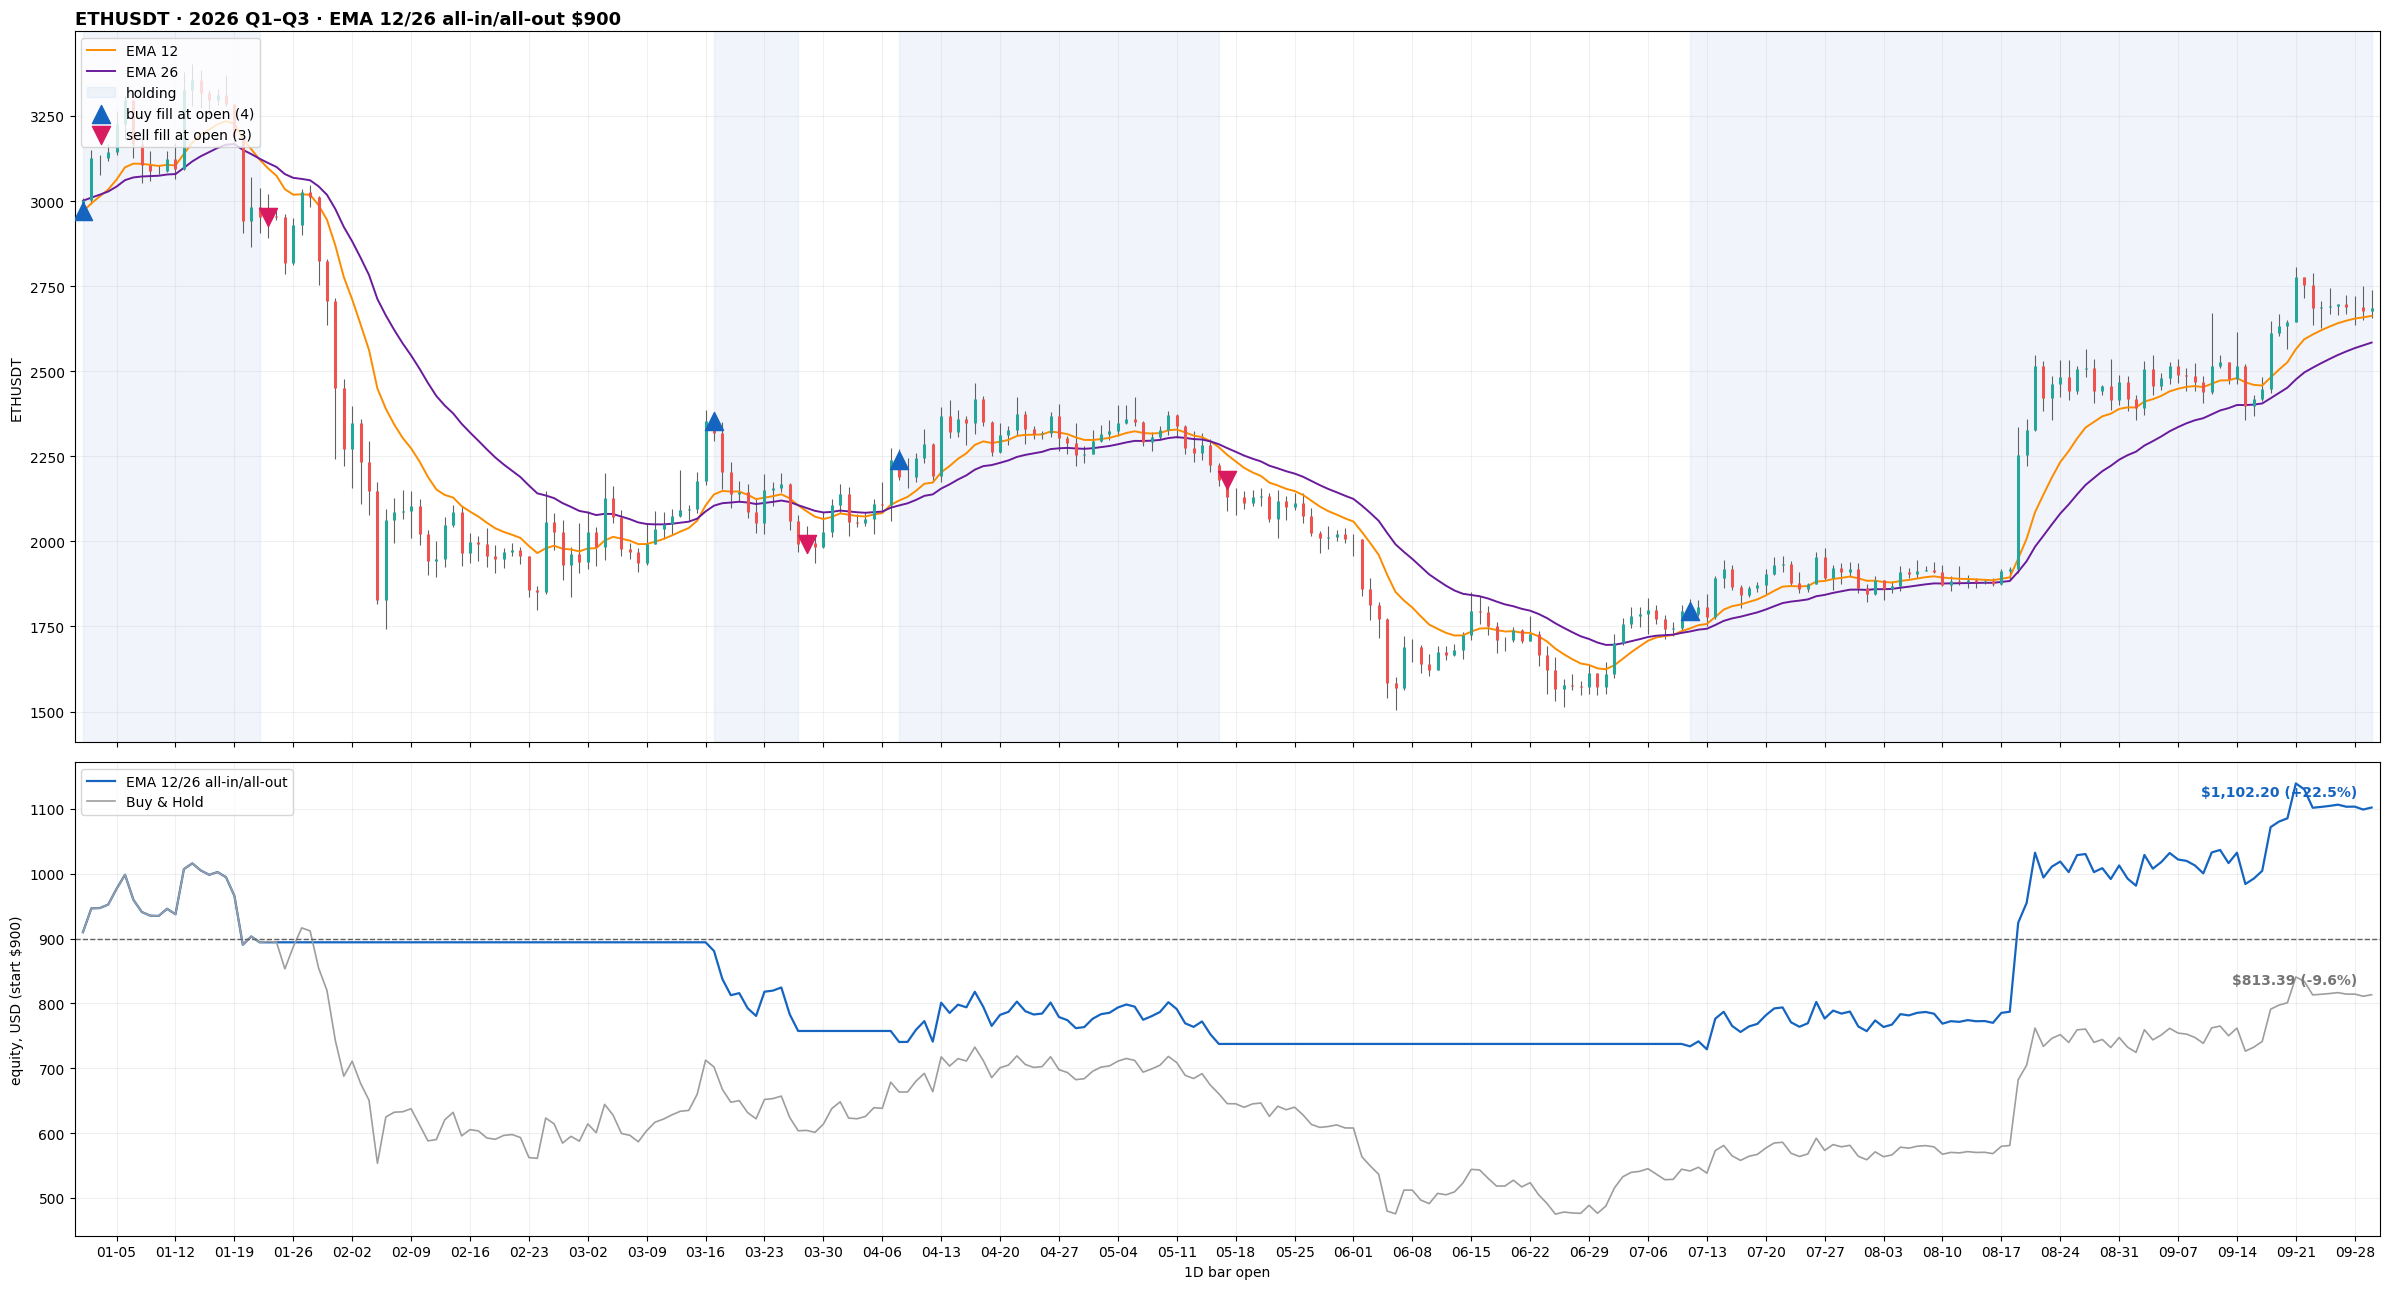

In [4]:
plot_ema_trades(bars["ETH"], runs["ETH"][0], passive["ETH"]["buy_hold"], f"ETHUSDT · {LABEL} · EMA 12/26 all-in/all-out ${CAPITAL:,.0f}", "ETHUSDT", CAPITAL)

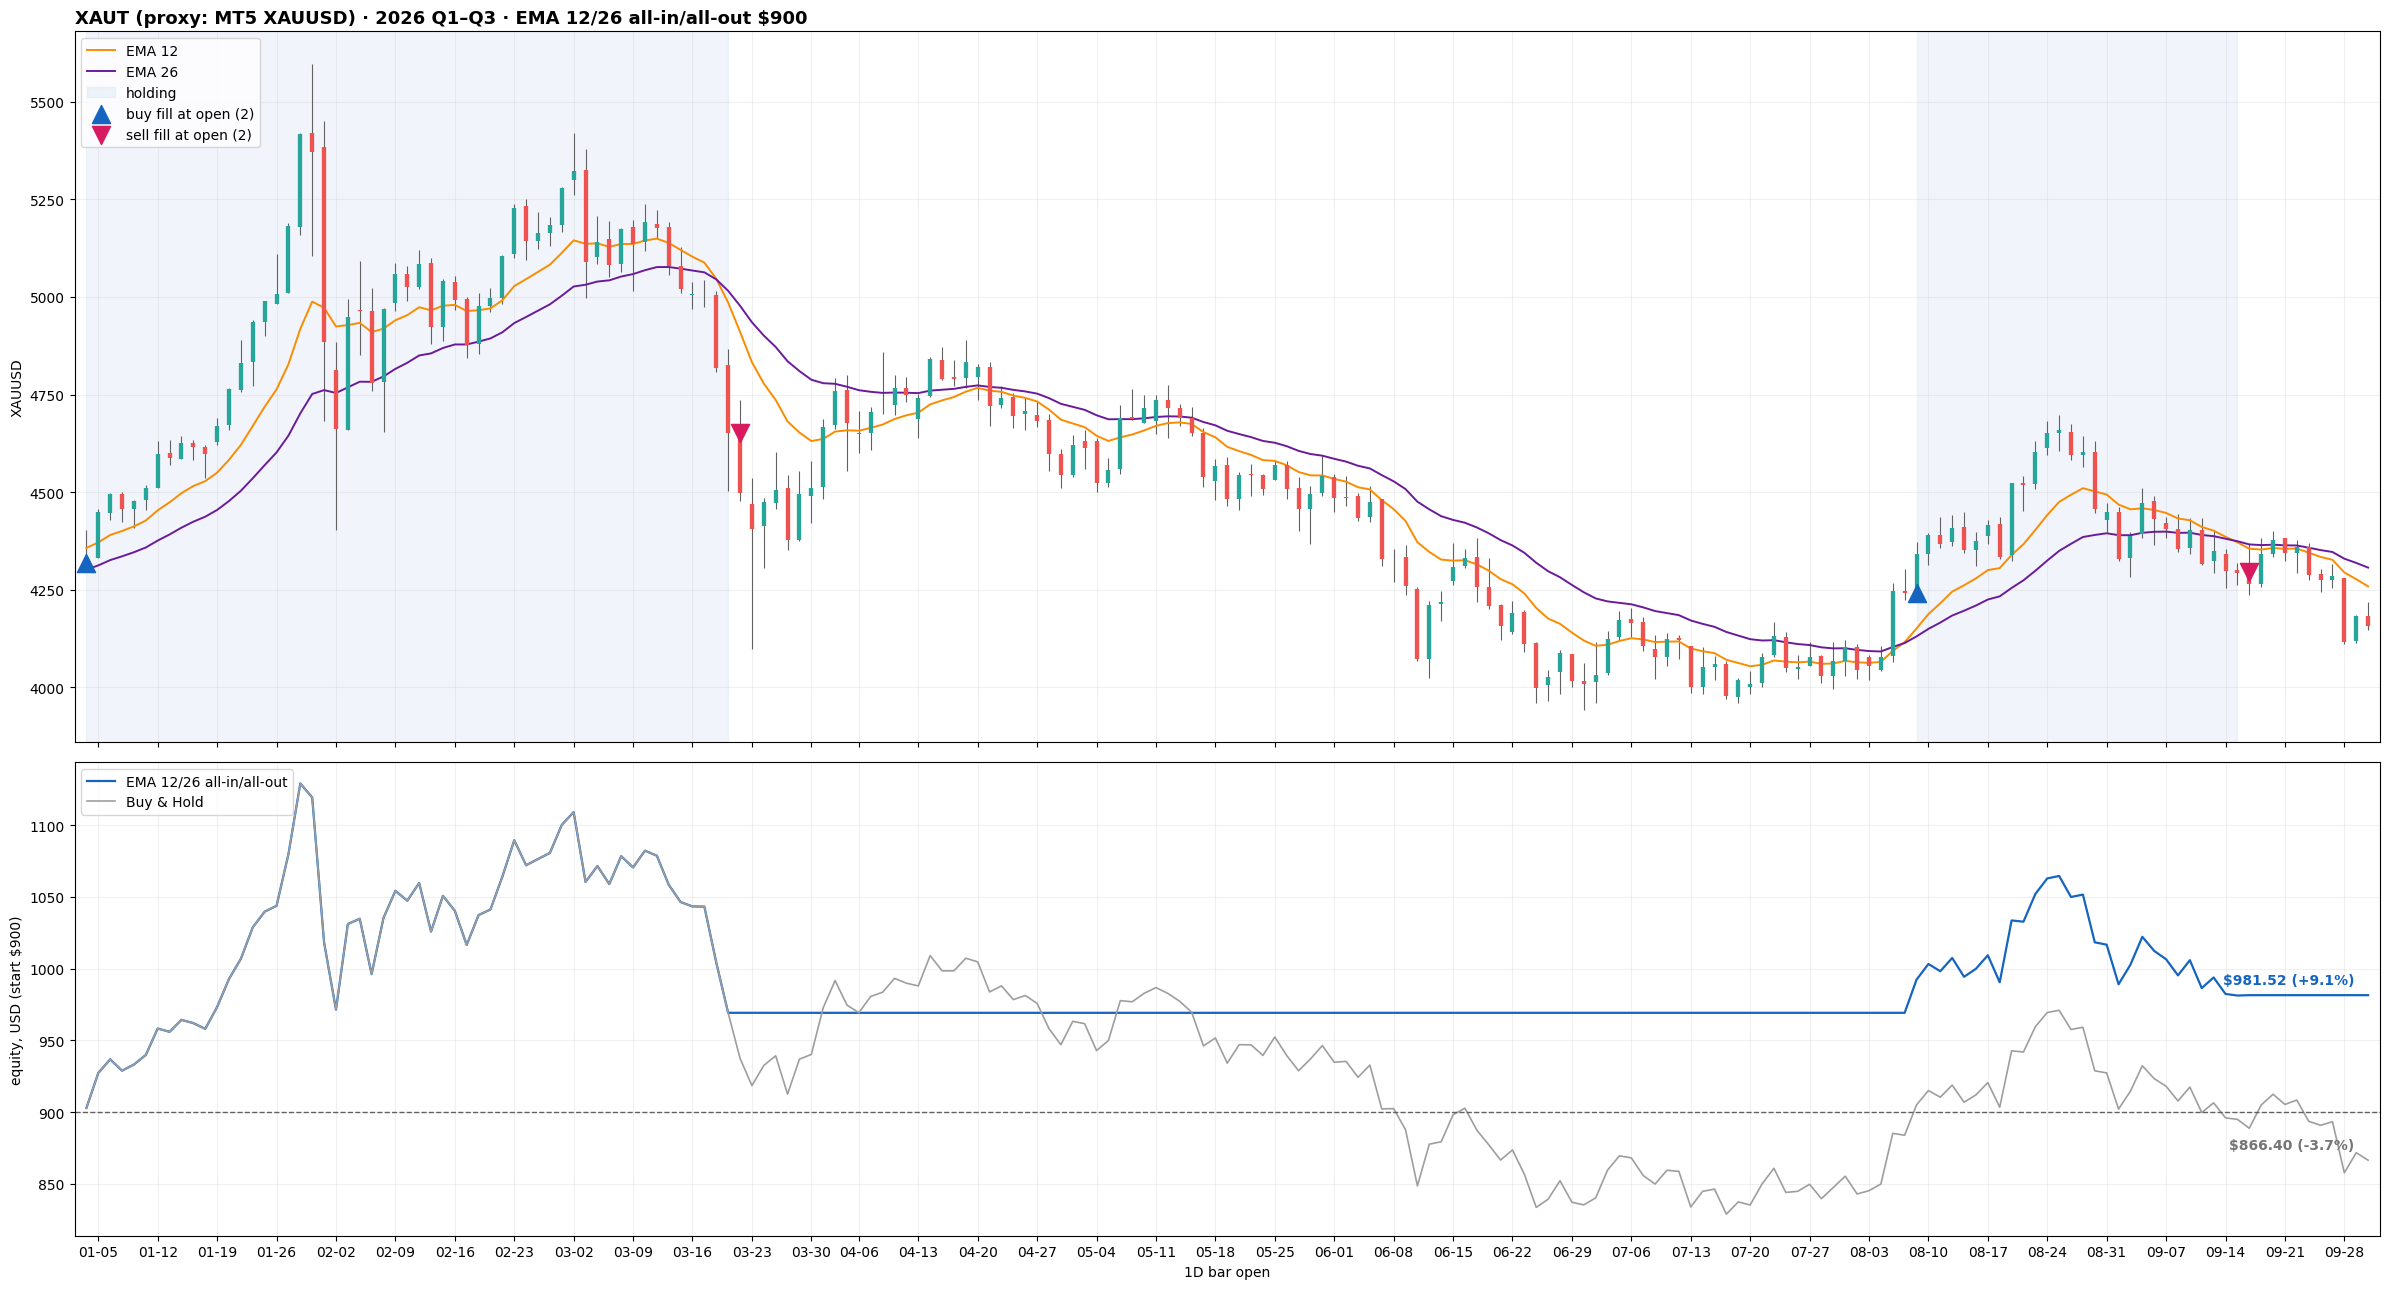

In [5]:
plot_ema_trades(bars["XAUT"], runs["XAUT"][0], passive["XAUT"]["buy_hold"], f"XAUT (proxy: MT5 XAUUSD) · {LABEL} · EMA 12/26 all-in/all-out ${CAPITAL:,.0f}", "XAUUSD", CAPITAL)

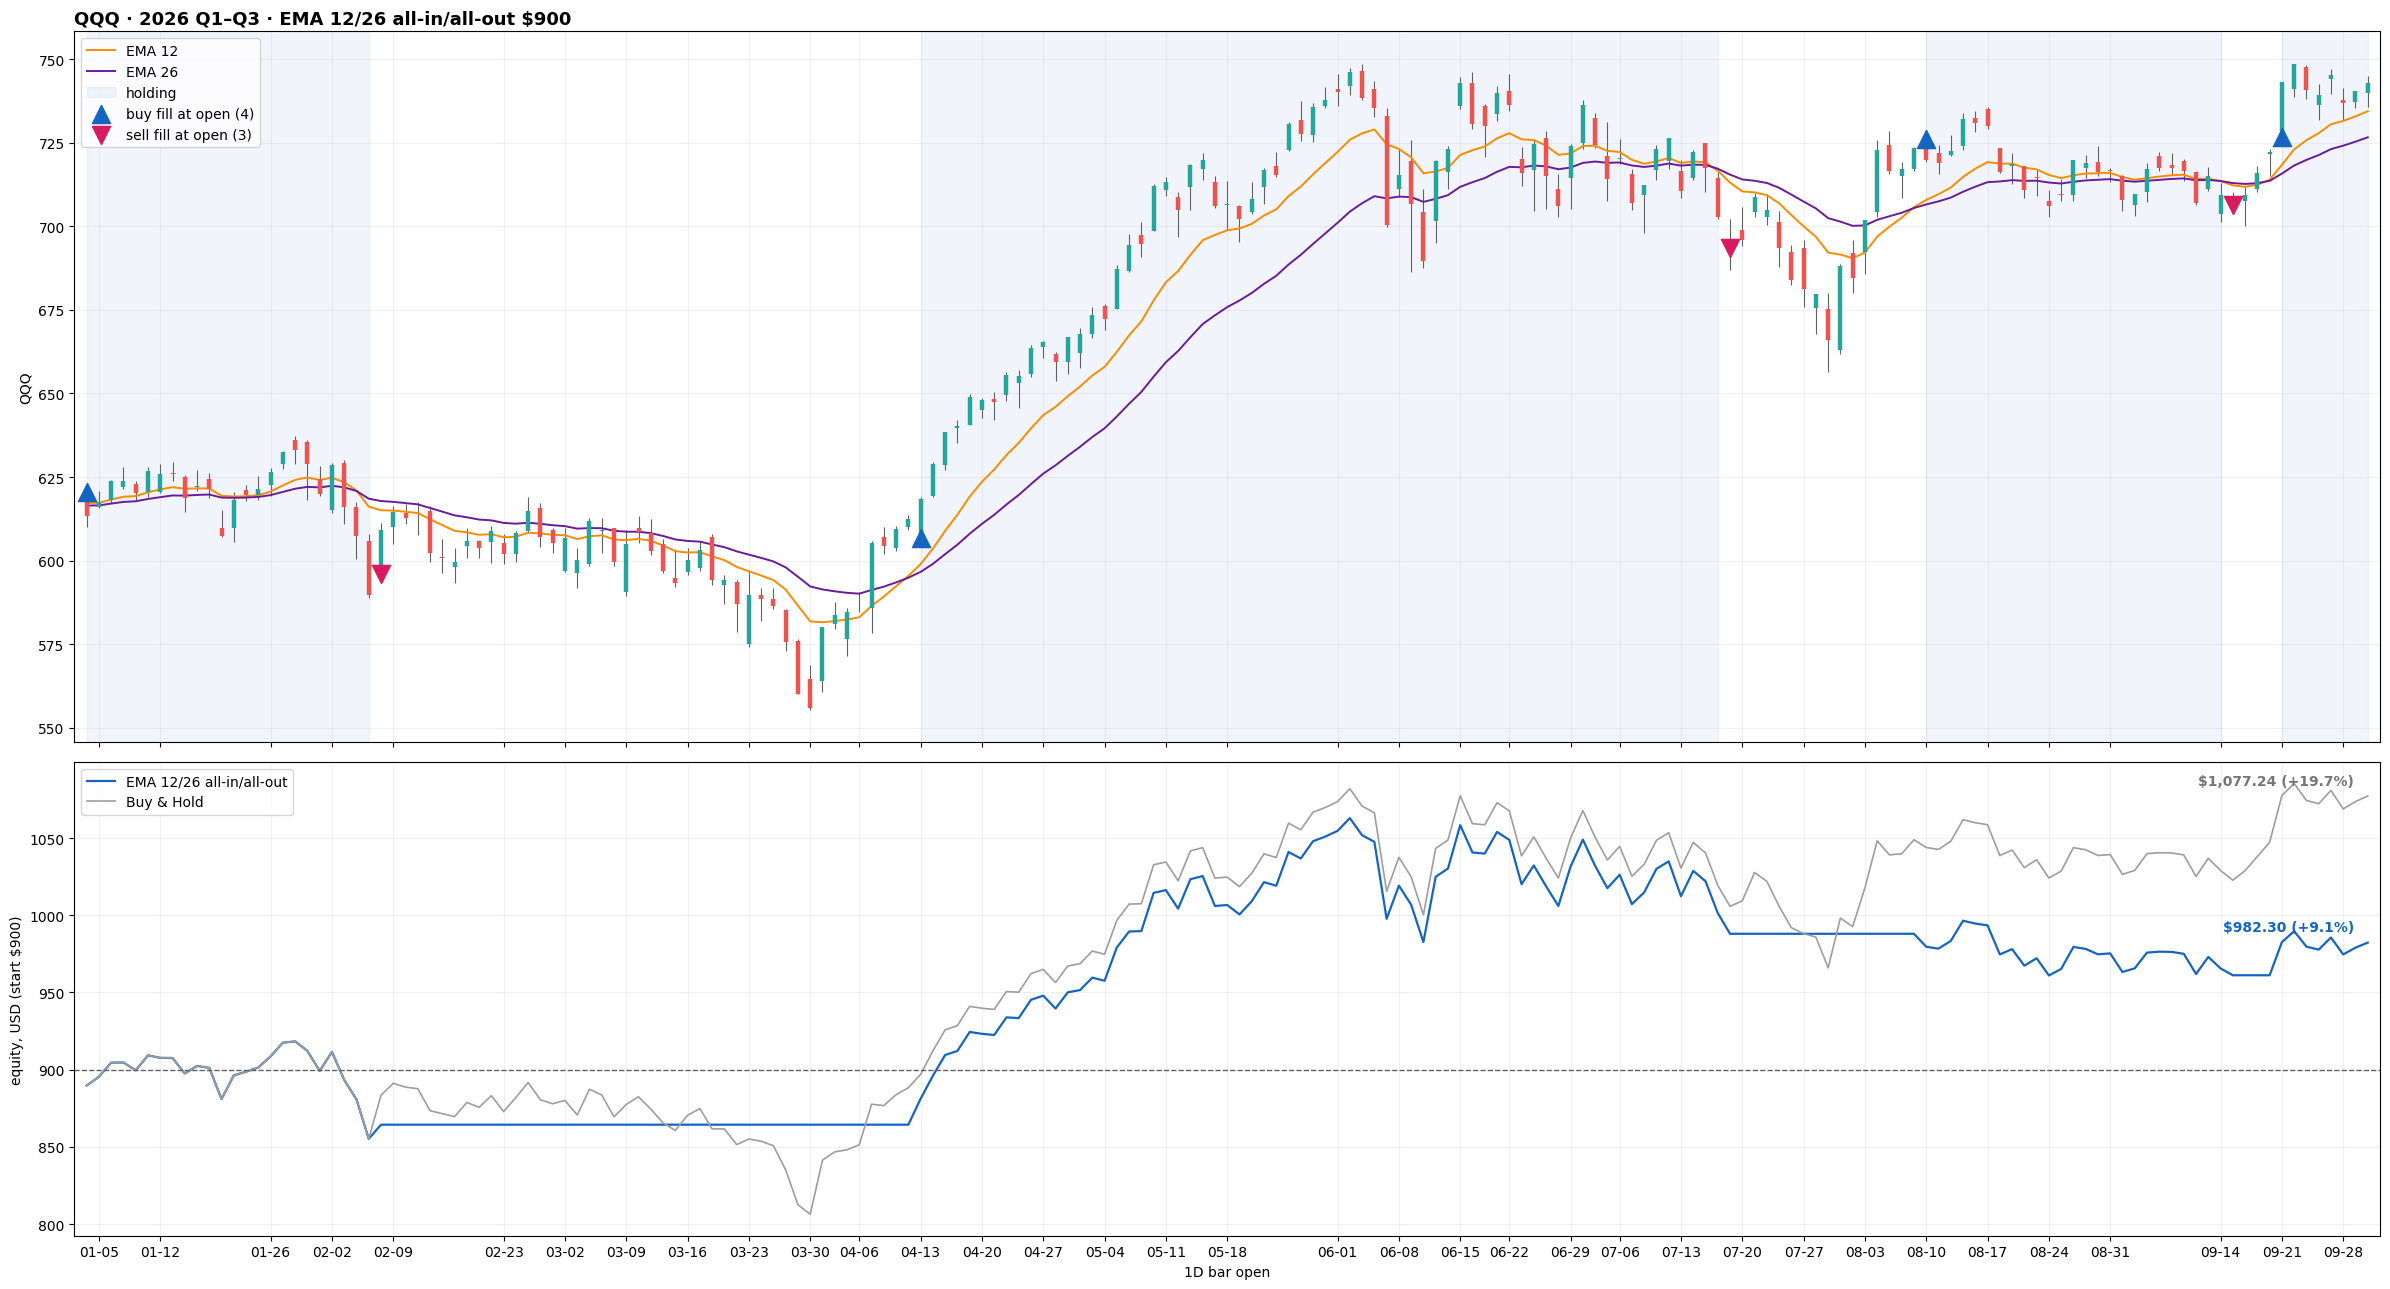

In [6]:
plot_ema_trades(bars["QQQ"], runs["QQQ"][0], passive["QQQ"]["buy_hold"], f"QQQ · {LABEL} · EMA 12/26 all-in/all-out ${CAPITAL:,.0f}", "QQQ", CAPITAL)